# **Machine Learning y Datos Faltantes**

Se abordan los fundamentos estadísticos de los datos faltantes, sus patrones y mecanismos de ausencia, y los métodos de imputación, con énfasis en la imputación múltiple mediante ecuaciones encadenadas (MICE). Se estudia cómo integrar la imputación en modelos de aprendizaje supervisado considerando la incertidumbre asociada a los valores imputados, la estimación de parámetros y la validación de modelos predictivo.

Duración: 2 horas

Modalidad: Taller teórico-práctico

Herramientas: `Python` y `R`, integrados mediante `rpy2`.


## **Configuración del entorno: Python y R**

Utilizaremos `R` para la imputación múltiple con mice y el ajuste de modelos estadísticos. `Python` se empleará para organizar la validación cruzada, evaluar el desempeño predictivo y visualizar los resultados.

Ambos lenguajes se integrarán mediante `rpy2`, que permite ejecutar código de `R` en `Google Colab` y transferir objetos entre los dos entornos.


In [31]:
# Instalación del paquete rpy2 para la integración de Python y R
%pip install -q rpy2

# Activación de la extensión para ejecutar código R
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [32]:
# Carga de paquetes de Python

# Manipulación de datos y operaciones numéricas
import numpy as np
import pandas as pd

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Validación cruzada estratificada repetida
from sklearn.model_selection import RepeatedStratifiedKFold

# Métricas de discriminación y desempeño predictivo
from sklearn.metrics import roc_auc_score, brier_score_loss

# Cálculo de la curva de calibración
from sklearn.calibration import calibration_curve

# Modelos de regresión para evaluar la calibración
import statsmodels.api as sm


In [33]:
# Instalación de paquetes de R
# Actualización del catálogo de paquetes disponibles
!sudo apt-get update -qq > /dev/null 2>&1

# Instalación de librerías precompiladas para imputación múltiple,
# exploración de datos faltantes, análisis factorial y clustering
!sudo apt-get install -y -qq --no-install-recommends \
    r-cran-mice \
    r-cran-jsonlite \
    r-cran-future \
    r-cran-furrr \
    r-cran-naniar \
    r-cran-misty > /dev/null

# Versión de R utilizada en el entorno
%R -n print(R.version.string)

[1] "R version 4.6.1 (2026-06-24)"


In [34]:
# Carga de paquetes de R
%%R

# Lectura de metadatos en formato JSON
library(jsonlite)

# Imputación múltiple mediante ecuaciones encadenadas
library(mice)

# Exploración y visualización de datos faltantes
library(naniar)
suppressPackageStartupMessages(library(misty))

# Consulta de las versiones de los paquetes de R
installed.packages()[c("mice", "naniar"), "Version"]

    mice   naniar 
"3.19.0"  "1.1.0" 


In [35]:
%%R

# Ampliación del ancho de impresión de los resultados de R
options(width = 200)


## **1. Fundamentos de los datos faltantes**

Los datos faltantes corresponden a valores que no se encuentran disponibles para determinadas variables y unidades de observación. Su presencia puede producir pérdida de información, sesgos en la estimación y alteraciones en los resultados de los algoritmos de Machine Learning. El tratamiento de estos datos depende de tres aspectos: el mecanismo que origina las ausencias, las relaciones entre las variables y el propósito del análisis, que puede ser inferencial, predictivo o exploratorio.

### **1.1. Patrones de ausencia**

Los **patrones de ausencia** describen cómo se distribuyen los valores faltantes en el conjunto de datos. Pueden ser univariados, cuando afectan una sola variable; monótonos, cuando las ausencias siguen un orden entre variables; o arbitrarios, cuando no presentan una estructura monótona.

### **1.2. Mecanismos de ausencia**

Los **mecanismos de ausencia** describen de qué depende la probabilidad de que un valor no sea observado. Sea
$$Y=(Y_{\mathrm{obs}},Y_{\mathrm{mis}})$$

- $Y_{\mathrm{obs}}$ representa los valores observados
- $Y_{\mathrm{mis}}$ los faltantes.
- $R$ la matriz de indicadores de observación, con $R_{kj}=1$ si el elmento $i,j$ está observado y $R_{kj}=0$ si está ausente.

**MCAR** (*Missing Completely At Random*): La ausencia no depende de los valores observados ni de los faltantes
$$
P(R\mid Y_{\mathrm{obs}},Y_{\mathrm{mis}})=P(R).
$$

**MAR** (*Missing At Random*): La ausencia puede depender de la información observada, pero no de los valores faltantes una vez condicionada a dicha información.
$$
P(R\mid Y_{\mathrm{obs}},Y_{\mathrm{mis}})
=
P(R\mid Y_{\mathrm{obs}}).
$$

**MNAR** (*Missing Not At Random*): La ausencia puede seguir dependiendo de los valores no observados, incluso después de considerar la información disponible.

$$
P(R\mid Y_{\mathrm{obs}},Y_{\mathrm{mis}})
$$
puede depender de $Y_{\mathrm{mis}}$.

El mecanismo de ausencia no puede determinarse de manera concluyente utilizando únicamente los datos observados.

### **1.3. Consecuencias sobre la inferencia y el Machine Learning**

Los datos faltantes pueden afectar los resultados de diferentes maneras:

- Inferencia estadística: pérdida de eficiencia, posibles sesgos y estimaciones inadecuadas de la incertidumbre.
- Aprendizaje supervisado: pérdida de información predictiva, cambios en las relaciones entre variables y deterioro de la generalización.
- Aprendizaje no supervisado: distorsión de distancias, componentes principales y estructuras de agrupamiento.

Estas consecuencias dependen del mecanismo de ausencia y del procedimiento utilizado. Una proporción pequeña de datos faltantes no garantiza que su efecto sea despreciable.

### **1.4. Estrategias generales de tratamiento**

Existen diferentes estrategias para analizar datos incompletos:

- **Eliminación:** exclusión de observaciones o variables incompletas. Puede ocasionar pérdida de información y sesgos, aunque el análisis de casos completos puede ser válido bajo determinadas condiciones.
- **Imputación simple:** sustitución de valores faltantes mediante media, mediana, moda, regresión u otros procedimientos. Generalmente no representa adecuadamente la incertidumbre de los valores imputados para fines inferenciales.
- **Métodos basados en modelos:** utilizan relaciones estadísticas entre variables e incluyen procedimientos de máxima verosimilitud, métodos bayesianos, imputación múltiple y algoritmos de Machine Learning. Algunos permiten analizar directamente datos incompletos sin generar una matriz completa.

La selección del procedimiento depende del objetivo del análisis, los supuestos del método y las características de los datos. No existe una estrategia universalmente superior.

### **1.5. Imputación única e imputación múltiple**

La **imputación única** asigna un solo valor a cada observación faltante. Aunque facilita la aplicación de algoritmos que requieren matrices completas, generalmente no incorpora la incertidumbre asociada a los valores imputados.

La **imputación múltiple** genera $m$ conjuntos de datos completos, con diferentes realizaciones plausibles de los valores faltantes. Comprende tres etapas:

1. **Imputación:** generación de los $m$ conjuntos completos.
2. **Análisis:** estimación del parámetro de interés en cada conjunto.
3. **Combinación:** integración de las estimaciones y sus varianzas.

### **1.6. Reglas de Rubin**

Sean $\hat{\theta}^{(l)}$ y $U^{(l)}$ la estimación de un parámetro y su varianza estimada en el conjunto imputado $l$, respectivamente.

**Estimación combinada:**

$$
\bar{\theta}=\frac{1}{m}\sum_{l=1}^{m}\hat{\theta}^{(l)}.
$$

**Varianza total:**

$$
T=\bar{U}+\left(1+\frac{1}{m}\right)B,
$$

donde $\bar{U}$ es la varianza media dentro de las imputaciones y $B$ es la varianza entre imputaciones:

$$
\bar{U}=\frac{1}{m}\sum_{l=1}^{m}U^{(l)}, \quad B=\frac{1}{m-1}\sum_{l=1}^{m}
\left(\hat{\theta}^{(l)}-\bar{\theta}\right)^2.
$$


La varianza total incorpora tanto la incertidumbre estimada dentro de cada conjunto imputado como la variabilidad entre imputaciones.

Estas reglas están formuladas para combinar estimadores y sus varianzas bajo determinados supuestos; no se aplican directamente a cualquier resultado de Machine Learning, como particiones de clustering o métricas de clasificación.


### **1.7. Medidas de severidad de los datos faltantes**

Estas medidas cuantifican el efecto de los datos faltantes sobre la incertidumbre de un parámetro estimado mediante imputación múltiple.

**Incremento relativo de la varianza (RIV)**

$$
r=\frac{(1+1/m)B}{\bar{U}}.
$$

Mide el incremento de la varianza debido a la incertidumbre asociada a los datos faltantes.

**Fracción de información faltante (FMI)**

$$
\gamma=\frac{r+2/(\nu+3)}{r+1},
$$

donde $\nu$ son los grados de libertad de la inferencia combinada.

Cuantifica la pérdida de información asociada a los datos faltantes. Toma valores entre 0 y 1; valores elevados indican mayor pérdida de información.

**Eficiencia relativa (RE)**

$$
RE\approx\left(1+\frac{\gamma}{m}\right)^{-1}.
$$

Mide la eficiencia aproximada de utilizar $m$ imputaciones frente a un número infinito. Valores cercanos a 1 indican mayor eficiencia.

Estas medidas dependen del parámetro estimado y del modelo de análisis, no únicamente del porcentaje de valores faltantes.

### **1.8. Imputación propia**

Un procedimiento de imputación múltiple se considera **propio**, en el sentido de Rubin, cuando representa adecuadamente la incertidumbre asociada a los valores faltantes y permite obtener inferencias válidas mediante las reglas de combinación, bajo los supuestos correspondientes.

Para ello, el procedimiento debe considerar tanto la variabilidad de los valores no observados como la incertidumbre de los parámetros utilizados para generar las imputaciones.

La generación de varios conjuntos completos no garantiza, por sí sola, una imputación propia. Algoritmos como KNN, Random Forest o boosting pueden producir buenas predicciones de valores faltantes, pero ello no demuestra que constituyan procedimientos de imputación propia.

Por tanto, deben distinguirse tres propósitos:

- **Reconstrucción:** aproximar los valores que no fueron observados.
- **Predicción:** mejorar el desempeño de un modelo de Machine Learning.
- **Inferencia:** estimar parámetros y cuantificar adecuadamente su incertidumbre.

Un método puede ser satisfactorio para uno de estos propósitos sin ser necesariamente adecuado para los demás.



## **2. Datos clínicos de pacientes con infarto de miocardio**

El conjunto de datos **Myocardial Infarction Complications**, contiene información clínica de 1.700 pacientes con infarto de miocardio, incluyendo antecedentes médicos, características clínicas, resultados de laboratorio y complicaciones hospitalarias.

Se busca predecir la mortalidad hospitalaria a partir de las características clínicas de los pacientes mediante técnicas de aprendizaje supervisado. Asimismo, se aplicarán métodos de reducción de dimensionalidad para explorar la estructura multivariada de los datos y técnicas de clustering para identificar grupos de pacientes con perfiles clínicos similares.

**Fuente:** Golovenkin et al. (2020). *Myocardial Infarction Complications*. UCI Machine Learning Repository. https://doi.org/10.24432/C53P5M

### **Variables seleccionadas**

Se utilizarán nueve variables: una respuesta binaria y ocho variables explicativas numéricas, binarias y ordinales.

| Variable | Descripción | Tipo |
|---|---|---|
| `mortalidad` | Mortalidad hospitalaria: No = sobrevivió; Sí = falleció. | Binaria |
| `edad` | Edad del paciente, en años. | Numérica |
| `sexo` | Sexo del paciente: mujer u hombre. | Binaria |
| `hipertension` | Antecedentes de hipertensión arterial, codificados de 0 a 3. | Ordinal |
| `tiempo_ingreso` | Tiempo transcurrido entre el inicio de los síntomas y el ingreso hospitalario, codificado en nueve categorías ordenadas. | Ordinal |
| `infartos_previos` | Número de infartos previos: 0, 1, 2 o 3 o más. | Ordinal |
| `insuficiencia_previa` | Antecedentes de insuficiencia cardíaca: No o Sí. | Binaria |
| `sistolica` | Presión arterial sistólica, en mmHg. | Numérica |
| `sodio` | Concentración de sodio en sangre, en mmol/L. | Numérica |

La presencia de variables de distinta naturaleza permite estudiar la especificación de modelos condicionales de imputación mediante MICE. En particular, se utilizarán métodos apropiados para cada tipo de variables.

In [36]:
%%R

# Descarga y lectura de los datos desde UCI

url = "https://archive.ics.uci.edu/static/public/579/myocardial+infarction+complications.zip"
archivo_zip = tempfile(fileext = ".zip")

download.file(url, archivo_zip, mode = "wb", quiet = TRUE)
archivo = unzip(archivo_zip, files = "MI.data", exdir = tempdir())

metadatos = fromJSON("https://archive.ics.uci.edu/api/dataset?id=579")

base = read.csv(
  archivo,
  header = FALSE,
  na.strings = "?",
  col.names = metadatos$data$variables$name
)

# Selección y codificación de variables clínicas
datos = data.frame(
  mortalidad = factor(
    ifelse(is.na(base$LET_IS), NA,
           ifelse(base$LET_IS > 0, "Sí", "No")),
    levels = c("No", "Sí")
  ),
  edad = base$AGE,
  sexo = factor(base$SEX, levels = c(0, 1),
                labels = c("Mujer", "Hombre")),
  hipertension = ordered(base$GB, levels = 0:3),
  tiempo_ingreso = ordered(base$TIME_B_S, levels = 1:9),
  infartos_previos = ordered(base$INF_ANAM, levels = 0:3),
  insuficiencia_previa = factor(
    ifelse(is.na(base$ZSN_A), NA,
           ifelse(base$ZSN_A > 0, "No", "Sí")),
    levels = c("No", "Sí")
  ),
  sistolica = base$S_AD_ORIT,
  sodio = base$NA_BLOOD
)

# Contrastes de tratamiento para las variables ordinales
contrasts(datos$hipertension) = contr.treatment(4)
contrasts(datos$tiempo_ingreso) = contr.treatment(9)
contrasts(datos$infartos_previos) = contr.treatment(4)

In [37]:
# Primeras diez observaciones del conjunto de datos
%R -n print(head(datos, 10))

   mortalidad edad   sexo hipertension tiempo_ingreso infartos_previos insuficiencia_previa sistolica sodio
1          No   77 Hombre            3              4                2                   Sí       180   138
2          No   55 Hombre            0              2                1                   Sí       120   132
3          No   52 Hombre            2              3                0                   Sí       180   132
4          No   68  Mujer            2              2                0                   No       120   146
5          No   60 Hombre            3              9                0                   Sí       160   132
6          No   64 Hombre            0              2                0                   Sí       140    NA
7          No   70 Hombre            2              1                1                   No       120    NA
8          No   65 Hombre            2              7                0                   Sí       145   136
9          No   60 Hombre   

In [38]:
# Resumen descriptivo de las variables
%R -n print(summary(datos))

 mortalidad      edad           sexo      hipertension tiempo_ingreso infartos_previos insuficiencia_previa   sistolica         sodio      
 No:1429    Min.   :26.00   Mujer : 635   0  :605      2      :360    0  :1060         No : 178             Min.   :  0.0   Min.   :117.0  
 Sí: 271    1st Qu.:54.00   Hombre:1065   1  : 11      9      :269    1  : 410         Sí :1468             1st Qu.:120.0   1st Qu.:133.0  
            Median :63.00                 2  :880      1      :198    2  : 147         NAs:  54             Median :130.0   Median :136.0  
            Mean   :61.86                 3  :195      3      :175    3  :  79                              Mean   :134.6   Mean   :136.6  
            3rd Qu.:70.00                 NAs:  9      6      :151    NAs:   4                              3rd Qu.:150.0   3rd Qu.:140.0  
            Max.   :92.00                              (Other):421                                          Max.   :260.0   Max.   :169.0  
            NAs    :

## **3. Exploración de valores faltantes**

La exploración de los valores faltantes permite cuantificar su frecuencia, identificar las variables afectadas y examinar los patrones de ausencia entre las observaciones.



In [39]:
%%R

# Cantidad y porcentaje de pacientes con información completa
casos = data.frame(
  Completos = sum(complete.cases(datos)),
  Incompletos = sum(!complete.cases(datos)),
  Porcentaje_completos = round(mean(complete.cases(datos)) * 100, 2)
)

print(casos)

  Completos Incompletos Porcentaje_completos
1      1012         688                59.53


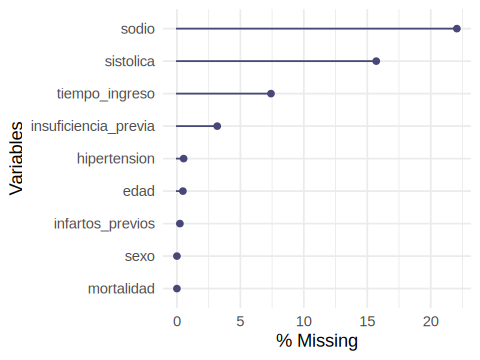

In [40]:
%%R -w 4 -h 3 -u in -r 120

# Porcentaje de valores faltantes por variable
print(gg_miss_var(datos, show_pct = TRUE))

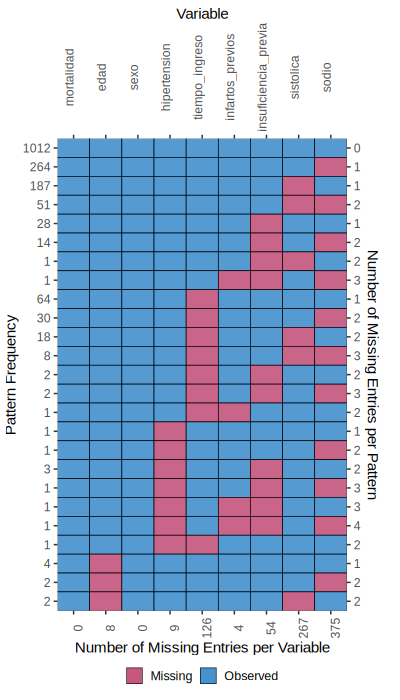

In [41]:
%%R -w 4 -h 7 -u in -r 100

# Visualización de los patrones de ausencia y sus frecuencias
na.pattern(datos, plot = TRUE, geom = "rotate", output = FALSE)

## **4. Imputación múltiple mediante MICE**

La imputación múltiple mediante ecuaciones encadenadas (Multiple Imputation by Chained Equations, MICE) permite tratar datos faltantes a través de modelos condicionales especificados para cada variable incompleta. El algoritmo utiliza el procedimiento FCS (Fully Conditional Specification), que actualiza iterativamente los valores imputados según las relaciones entre las variables. Su flexibilidad permite incorporar modelos estadísticos y algoritmos de Machine Learning adecuados para variables numéricas, binarias, nominales y ordinales.

### **Algoritmo**

>**Entrada:** conjunto de datos incompleto $Y_{(n\times p)}$, número de imputaciones $m$ y número de iteraciones $T$.
>
>**Para cada imputación** $l=1,\ldots,m$:
>
>1. Inicializar los valores faltantes de todas las variables.
>
>2. **Para cada iteración** $t=1,\ldots,T$:
>
>   **Para cada variable incompleta** $Y_j$:
>
>   - Ajustar el modelo condicional $P(Y_j\mid Y_{-j},\theta_j)$ utilizando los valores observados de $Y_j$.
>   - Incorporar la incertidumbre correspondiente al método de imputación.
>   - Generar nuevos valores para los faltantes de $Y_j$.
>   - Actualizar $Y_j$ antes de continuar con la siguiente variable.
>
>3. Guardar el conjunto de datos completado $Y^{(l)}$.
>
>**Salida:** $m$ conjuntos de datos completos:
>
>$$
 Y^{(1)},Y^{(2)},\ldots,Y^{(m)}.
 $$

Los métodos convencionales de imputación múltiple, como MICE, se aplican generalmente bajo el supuesto MAR.

### **Algoritmo PMM (*Predictive Mean Matching*)**

>Algoritmo de imputación para variables numéricas:
>
>1. Sea $n_0$ y $n_1$ el número de valores faltantes y observados de $Y_j$.
>
>2. Calcular la matriz de productos cruzados: $S=(Y_{-j}^{\mathrm{obs}})^\top Y_{-j}^{\mathrm{obs}}$.
>
>3. Calcular la matriz inversa regularizada: $V=\left(S \kappa\operatorname{diag}(S)\right)^{-1}$, donde $\kappa$ es un parámetro de regularización (*ridge*).
>
>4. Estimar los coeficientes de regresión: $\hat{\boldsymbol{\beta}}_{(q\times 1)} =V(Y_{-j}^{\mathrm{obs}})^\top Y_j^{\mathrm{obs}}$
>
>5. Generar un vector aleatorio normal estándar: $\dot{\boldsymbol{z}}_1\sim N_q(\boldsymbol{0},I_q)$.
>
>6. Obtener $V^{1/2}$ mediante la descomposición de Cholesky de $V$.
>
>7. Generar los coeficientes aleatorios de regresión:
>  $$
   \dot{\boldsymbol{\beta}} = \hat{\boldsymbol{\beta}} + \dot{\sigma}V^{1/2}\dot{\boldsymbol{z}}_1,
   $$
>   donde $\dot{\sigma}$ es una extracción aleatoria de la desviación estándar residual:
>   $$
   \dot{\sigma}=\sqrt{\frac{\mathrm{SCR}}{g}},
   \qquad g\sim\chi^2_{n_1-q},
   $$
>   con $\mathrm{SCR} = \left(Y_j^{\mathrm{obs}}-Y_{-j}^{\mathrm{obs}}\hat{\boldsymbol{\beta}}\right)^\top \left(Y_j^{\mathrm{obs}}-Y_{-j}^{\mathrm{obs}}\hat{\boldsymbol{\beta}}\right)$.
>
>8. Calcular las distancias entre las predicciones de los casos observados y faltantes:
>   $$
   \dot{\eta}(k,h)= \left|
   Y_{-j,[k]}^{\mathrm{obs}}\hat{\boldsymbol{\beta}} -
   Y_{-j,[h]}^{\mathrm{mis}}\dot{\boldsymbol{\beta}} \right|,
   $$
>   para $k=1,\ldots,n_1$ y $h=1,\ldots,n_0$.
>
>9. Construir $n_0$ conjuntos $Z_h$, cada uno con los $d$ donantes candidatos que minimizan la suma de distancias $\sum_d\dot{\eta}(k,h)$.
>
> 10. Seleccionar aleatoriamente un donante $k_h$ de cada conjunto $Z_h$ e imputar el valor observado del donante seleccionado:
$$
Y_{hj}^{\mathrm{imp}}=Y_{k_hj}^{\mathrm{obs}}, \qquad h=1,\ldots,n_0.
$$

### **Variables categóricas**

Para las variables categóricas, mice utiliza modelos de imputación según su naturaleza: regresión logística binaria (logreg) para variables con dos categorías, regresión logística multinomial (polyreg) para variables nominales con más de dos categorías y regresión logística ordinal de probabilidades proporcionales (polr) para variables ordenadas. En cada caso, los valores faltantes se generan mediante procedimientos estocásticos basados en las probabilidades estimadas, incorporando incertidumbre en las imputaciones.


In [42]:
%%R

# Imputación múltiple

# Métodos predeterminados:
# - pmm: variables numéricas
# - logreg: variables binarias
# - polyreg: variables nominales
# - polr: variables ordinales

imputaciones = futuremice(
  datos,
  m = 5,
  maxit = 15,
  defaultMethod = c("pmm", "logreg", "polyreg", "polr"),
  n.core = 2,
  parallelseed = 123
)

In [43]:
%%R imputaciones$imp$edad

      1  2  3  4  5
71   50 75 68 67 44
104  64 62 39 40 41
485  71 69 72 45 64
1201 53 55 50 72 37
1292 73 65 70 71 65
1304 57 52 45 62 54
1360 77 51 53 42 40
1391 67 60 63 63 43


### **4.1. Diagnóstico de convergencia y evaluación de imputaciones**

Después de aplicar `mice()`, conviene examinar la convergencia de las cadenas y comparar las distribuciones observadas e imputadas.

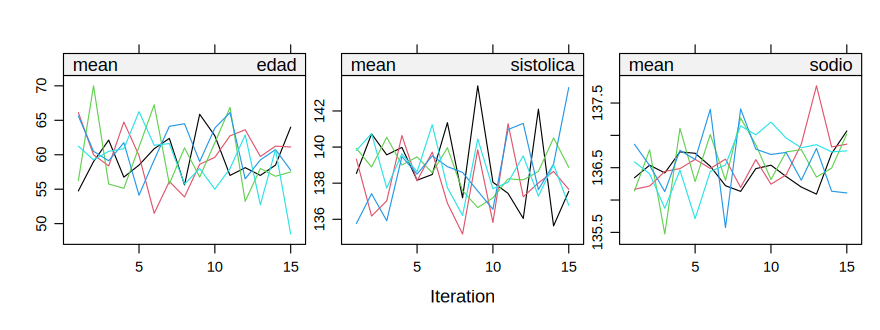

In [44]:
%%R -w 8 -h 3 -u in -r 110

# Convergencia de las medias de las variables numéricas
print(plot(
  imputaciones,
  edad + sistolica + sodio ~ .it | .ms,
  subset = .ms == "mean",
  layout = c(3, 1)
))

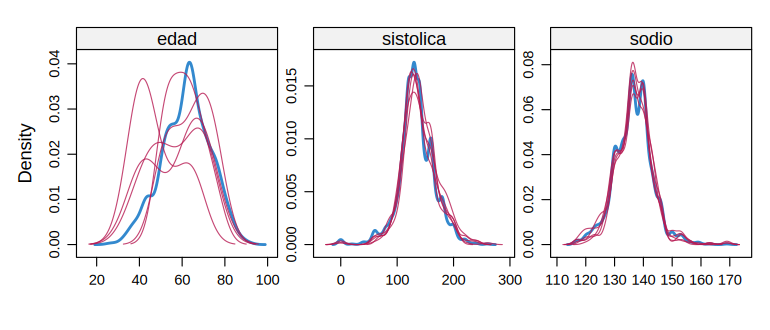

In [45]:
%%R -w 7 -h 3 -u in -r 110

# Distribuciones de las variables numéricas
densityplot(imputaciones, ~ edad + sistolica + sodio)

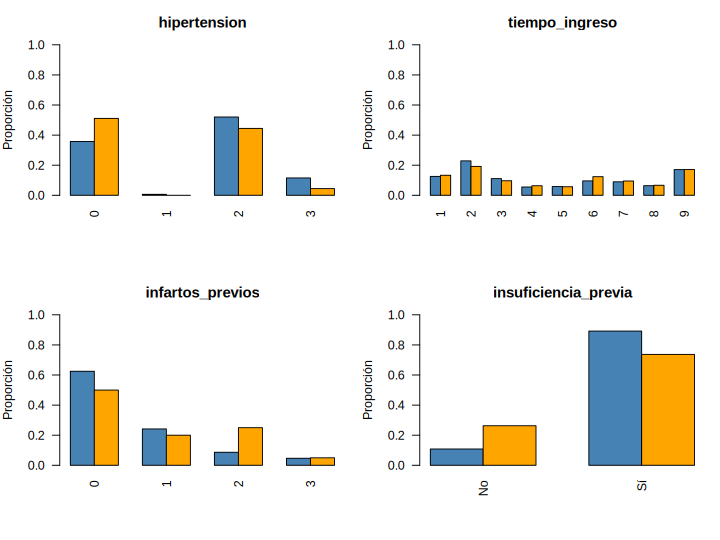

In [46]:
%%R -w 8 -h 6 -u in -r 90

# Variables categóricas
variables = c(
  "hipertension", "tiempo_ingreso", "infartos_previos", "insuficiencia_previa"
)

# Comparación de distribuciones observadas e imputadas
par(mfrow = c(2, 2), mar = c(5, 4, 3, 1))

for(variable in variables){
  niveles = levels(datos[[variable]])
  # Proporciones de los valores observados
  observados = prop.table(
    table(factor(datos[[variable]], levels = niveles))
  )
  # Proporciones de los valores imputados en las cinco cadenas
  valores_imputados = unlist(
    lapply(imputaciones$imp[[variable]], as.character),
    use.names = FALSE
  )
  imputados = prop.table(
    table(factor(valores_imputados, levels = niveles))
  )
  # Gráfico comparativo
  barplot(
    rbind(Observados = observados, Imputados = imputados),
    beside = TRUE,
    main = variable,
    ylab = "Proporción",
    ylim = c(0, 1),
    las = 2,
    col = c("steelblue", "orange")
  )
}

par(mfrow = c(1, 1))

## **5. Machine Learning supervisado con datos faltantes**

Se utilizará regresión logística binaria para predecir la mortalidad de los pacientes a partir de ocho variables clínicas, algunas de las cuales presentan valores faltantes.

El modelo se define como:

$$
\log\left(\frac{p_k}{1-p_k}\right) = \beta_0+\sum_{j=1}^{q}\beta_j x_{kj}
$$

donde $p_k$ es la probabilidad de mortalidad del paciente $k$, y $x_{kj}$ representa las variables predictoras, incluidas las indicadoras correspondientes a las variables categóricas.

Primero se ajustará la regresión logística sobre los conjuntos imputados mediante MICE, combinando sus estimaciones mediante las reglas de Rubin. Después se evaluará su desempeño predictivo mediante validación cruzada estratificada repetida, siguiendo el procedimiento de Mertens et al. (2020).



### **5.1. Ajuste de regresión logística con imputación múltiple**

Se ajustará una regresión logística sobre cada uno de los cinco conjuntos imputados mediante MICE. Los coeficientes se combinarán mediante las reglas de Rubin para obtener estimaciones, errores estándar, intervalos de confianza del 95 % y *odds ratios*.


In [47]:
%%R

# Ajuste de regresión logística en los cinco conjuntos imputados
modelos_logisticos = with(
  imputaciones,
  glm(
    mortalidad ~ edad + sexo + hipertension +
      tiempo_ingreso + infartos_previos + insuficiencia_previa +
      sistolica + sodio,
    family = binomial()
  )
)

# Combinación de estimaciones mediante las reglas de Rubin
modelo_combinado = pool(modelos_logisticos)

In [48]:
%%R

# Resultados inferenciales de la regresión logística
tabla_regresion = summary(
  modelo_combinado,
  conf.int = TRUE
)

# Odds ratios e intervalos de confianza
tabla_regresion$OR = exp(tabla_regresion$estimate)
tabla_regresion$OR_inferior = exp(tabla_regresion$`2.5 %`)
tabla_regresion$OR_superior = exp(tabla_regresion$`97.5 %`)

# Selección de resultados inferenciales
tabla_regresion = tabla_regresion[
  , c("term", "estimate", "std.error", "p.value",
      "OR", "OR_inferior", "OR_superior")
]

# Componentes de varianza e información faltante
tabla_informacion = as.data.frame(modelo_combinado$pooled)[
  , c("term", "ubar", "b", "t", "riv", "lambda", "fmi")
]

# Eficiencia relativa de la imputación múltiple
tabla_informacion$RE = 1 / (
  1 + tabla_informacion$fmi / imputaciones$m
)

# Redondeo de ambas tablas
for (tabla in c("tabla_regresion", "tabla_informacion")) {
  resultado = get(tabla)
  numericas = vapply(resultado, is.numeric, logical(1))
  resultado[numericas] = lapply(resultado[numericas], round, digits = 4)
  assign(tabla, resultado)
}

# Presentación de resultados
cat("Componentes de varianza e información faltante\n")
print(tabla_informacion, row.names = FALSE)

cat("\nRegresión logística e inferencia\n")
print(tabla_regresion, row.names = FALSE)

Componentes de varianza e información faltante
                   term   ubar      b      t    riv lambda    fmi     RE
            (Intercept) 2.7463 0.3933 3.2183 0.1719 0.1467 0.1568 0.9696
                   edad 0.0001 0.0000 0.0001 0.0181 0.0178 0.0191 0.9962
             sexoHombre 0.0264 0.0004 0.0268 0.0167 0.0164 0.0177 0.9965
          hipertension2 1.1893 0.0116 1.2032 0.0117 0.0116 0.0128 0.9974
          hipertension3 0.0322 0.0024 0.0351 0.0914 0.0837 0.0881 0.9827
          hipertension4 0.0599 0.0049 0.0659 0.0989 0.0900 0.0948 0.9814
        tiempo_ingreso2 0.0546 0.0078 0.0639 0.1715 0.1464 0.1565 0.9696
        tiempo_ingreso3 0.0730 0.0034 0.0770 0.0555 0.0526 0.0551 0.9891
        tiempo_ingreso4 0.1077 0.0115 0.1215 0.1278 0.1133 0.1202 0.9765
        tiempo_ingreso5 0.0931 0.0014 0.0947 0.0179 0.0176 0.0189 0.9962
        tiempo_ingreso6 0.0823 0.0101 0.0944 0.1480 0.1289 0.1372 0.9733
        tiempo_ingreso7 0.1442 0.0151 0.1623 0.1255 0.1115 0.1181 0.9769
    

### Predicción para nuevos pacientes

Se estimará la probabilidad de mortalidad de dos nuevos pacientes con información clínica parcialmente incompleta. MICE imputará los predictores faltantes sin utilizar a estos pacientes para ajustar los modelos de imputación.

Las probabilidades obtenidas con los cinco modelos logísticos ajustados previamente se combinarán mediante su promedio.

In [49]:
%%R

# Nuevos pacientes con información clínica completa
nuevos = data.frame(
  edad = c(65, 72),
  sexo = factor(
    c("Hombre", "Mujer"),
    levels = levels(datos$sexo)
  ),
  hipertension = ordered(
    c(1, 2),
    levels = levels(datos$hipertension)
  ),
  tiempo_ingreso = ordered(
    c(3, 5),
    levels = levels(datos$tiempo_ingreso)
  ),
  infartos_previos = ordered(
    c(1, 2),
    levels = levels(datos$infartos_previos)
  ),
  insuficiencia_previa = factor(
    c("No", "Sí"),
    levels = levels(datos$insuficiencia_previa)
  ),
  sistolica = c(120, 135),
  sodio = c(138, 140)
)

# Predicción con los cinco modelos logísticos ajustados
probabilidades_nuevas = sapply(
  modelos_logisticos$analyses,
  function(modelo) {
    predict(
      modelo,
      newdata = nuevos,
      type = "response"
    )
  }
)

# Combinación de las probabilidades predichas
resultados_nuevos = data.frame(
  paciente = seq_len(nrow(nuevos)),
  probabilidad_mortalidad = rowMeans(probabilidades_nuevas)
)

# Presentación de los pacientes y sus predicciones
print(nuevos, row.names = FALSE)
cat("\n")
print(resultados_nuevos, row.names = FALSE)

 edad   sexo hipertension tiempo_ingreso infartos_previos insuficiencia_previa sistolica sodio
   65 Hombre            1              3                1                   No       120   138
   72  Mujer            2              5                2                   Sí       135   140

 paciente probabilidad_mortalidad
        1               0.4458665
        2               0.2899233


### **5.2. Imputación en entrenamiento y validación**

En cada partición, la imputación se realiza utilizando la información de los pacientes de entrenamiento, incluida su mortalidad observada.

La mortalidad de los pacientes de validación se oculta antes de ejecutar MICE. Sus valores imputados provisionalmente pueden intervenir en la imputación de los predictores, pero se descartan al finalizar el procedimiento.

De esta manera, las respuestas reales de validación no intervienen en la imputación ni en el entrenamiento del modelo, evitando la fuga de información.

### **5.3. Validación cruzada estratificada repetida**

Se utilizarán cinco particiones y diez repeticiones. En cada repetición se generan nuevas particiones, conservando aproximadamente la proporción de pacientes fallecidos.

Cada paciente participa una vez en la validación de cada repetición, por lo que se obtendrán diez probabilidades predichas fuera de muestra por paciente.

In [50]:
# Recuperación de la respuesta desde R
%R -o mortalidad_cv mortalidad_cv = as.character(datos$mortalidad)

array(['No', 'No', 'No', ..., 'Sí', 'Sí', 'Sí'],
      shape=(1700,), dtype='<U2')

In [51]:
# Configuración de la validación cruzada
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=123
)

# Generación de las particiones estratificadas
y = np.asarray(mortalidad_cv)
particiones = list(cv.split(np.zeros(len(y)), y))

# Organización de las particiones para su utilización en R
folds_cv = np.zeros((len(y), 10), dtype=int)

for i, (_, idx_validacion) in enumerate(particiones):
    repeticion = i // 5
    fold = i % 5 + 1
    folds_cv[idx_validacion, repeticion] = fold

### **5.4. Imputación, entrenamiento y predicción**

En cada partición se realizará una imputación mediante MICE, se ajustará una regresión logística con las observaciones de entrenamiento y se calcularán las probabilidades de mortalidad de los pacientes de validación.

El procedimiento se ejecutará sobre las 50 particiones, generando diez predicciones fuera de muestra para cada paciente.

In [52]:
%%R -i folds_cv

# Configuración de los modelos condicionales
predictores = make.predictorMatrix(datos)

# Matriz para almacenar las predicciones
predicciones_cv = matrix(
  NA_real_,
  nrow = nrow(datos),
  ncol = ncol(folds_cv)
)

# Validación cruzada repetida
for (r in seq_len(ncol(folds_cv))) {

  for (f in 1:5) {

    # Identificación de entrenamiento y validación
    idx_validacion = which(folds_cv[, r] == f)
    idx_entrenamiento = which(folds_cv[, r] != f)

    # Ocultamiento de la respuesta en validación
    datos_cv = datos
    datos_cv$mortalidad[idx_validacion] = NA

    # Configuración de los métodos de imputación
    metodos = make.method(
        datos_cv,
        defaultMethod = c("pmm", "logreg", "polyreg", "polr")
        )

    # Exclusión de validación del ajuste de MICE
    ignorar = seq_len(nrow(datos_cv)) %in% idx_validacion

    # Imputación de entrenamiento y validación
    imputacion_cv = mice(
      datos_cv,
      m = 1,
      maxit = 5,
      method = metodos,
      predictorMatrix = predictores,
      ignore = ignorar,
      seed = 123 + (r - 1) * 5 + f,
      printFlag = FALSE
    )

    # Recuperación de los datos completados
    datos_completos = complete(imputacion_cv, 1)

    # Ajuste de la regresión logística
    modelo_cv = glm(
      mortalidad ~ .,
      data = datos_completos[idx_entrenamiento, ],
      family = binomial()
    )

    # Predicciones fuera de muestra
    predicciones_cv[idx_validacion, r] = predict(
      modelo_cv,
      newdata = datos_completos[idx_validacion, ],
      type = "response"
    )
  }
}
# Verificación de predicciones faltantes por repetición
print(colSums(is.na(predicciones_cv)))


 [1] 0 0 0 0 0 0 0 0 0 0


In addition: There were 50 or more warnings (use warnings() to see the first 50)


### **5.5. Combinación de predicciones**

Cada paciente dispone de una probabilidad de mortalidad predicha en cada repetición de la validación cruzada. Estas probabilidades se combinan mediante su promedio:

$$
\bar{p}_k = \frac{1}{K}\sum_{r=1}^{K}\hat{p}_k^{(r)}
$$

donde $\hat{p}_k^{(r)}$ es la probabilidad predicha para el paciente $k$ en la repetición $r$, y $K=10$.

In [53]:
%%R

# Combinación de las probabilidades predichas
resultados_cv = data.frame(
  mortalidad = datos$mortalidad,
  probabilidad = rowMeans(predicciones_cv)
)

# Primeras diez observaciones
print(head(resultados_cv, 10))

   mortalidad probabilidad
1          No   0.17853468
2          No   0.12431404
3          No   0.03378706
4          No   0.38642017
5          No   0.02974883
6          No   0.08426972
7          No   0.49890586
8          No   0.04253179
9          No   0.03599025
10         No   0.23693065


### **5.6. Evaluación del desempeño predictivo**

El desempeño del modelo se evaluará a partir de las probabilidades predichas fuera de muestra mediante tres criterios:

- **AUC-ROC:** capacidad del modelo para discriminar entre pacientes fallecidos y sobrevivientes.
- **Brier Score:** error cuadrático medio de las probabilidades predichas.
- **Calibración:** concordancia entre las probabilidades predichas y las frecuencias observadas de mortalidad.

Las métricas se calcularán a partir de las probabilidades combinadas de las diez repeticiones.

In [54]:
# Transferencia de predicciones y respuestas observadas
%R -o predicciones_cv
%R -o mortalidad_cv mortalidad_cv = as.character(datos$mortalidad)

array(['No', 'No', 'No', ..., 'Sí', 'Sí', 'Sí'],
      shape=(1700,), dtype='<U2')

In [55]:
# Combinación de las probabilidades predichas
p = np.asarray(predicciones_cv).mean(axis=1)

# Codificación binaria de la mortalidad
y_observada = (np.asarray(mortalidad_cv) == "Sí").astype(int)

# Evaluación del desempeño predictivo
auc = roc_auc_score(y_observada, p)
brier = brier_score_loss(y_observada, p)

print(f"AUC-ROC: {auc:.4f}")
print(f"Brier Score: {brier:.4f}")

AUC-ROC: 0.7597
Brier Score: 0.1135


### **Calibración del modelo**

El intercepto y la pendiente de calibración se estiman mediante regresión logística:

$$
\operatorname{logit}\{P(Y_k=1)\}
=
\alpha+\gamma\operatorname{logit}(\hat p_k)
$$

donde $\hat p_k$ es la probabilidad predicha de mortalidad. La pendiente ideal es $\gamma=1$. El intercepto de calibración se estima por separado, fijando la pendiente en uno, y su valor ideal es 0.

Un intercepto positivo indica subestimación global del riesgo; una pendiente inferior a uno indica que las probabilidades predichas tienden a ser demasiado extremas.

In [56]:
# Transformación logit de las probabilidades predichas
p_ajustada = np.clip(p, 1e-8, 1 - 1e-8)
logit_p = np.log(p_ajustada / (1 - p_ajustada))

# Intercepto de calibración con pendiente fija en uno
modelo_intercepto = sm.GLM(
    y_observada,
    np.ones((len(p), 1)),
    family=sm.families.Binomial(),
    offset=logit_p
).fit()

# Pendiente de calibración
modelo_calibracion = sm.GLM(
    y_observada,
    sm.add_constant(logit_p),
    family=sm.families.Binomial()
).fit()

# Resultados de calibración
print(f"Intercepto de calibración: {modelo_intercepto.params[0]:.4f}")
print(f"Pendiente de calibración: {modelo_calibracion.params[1]:.4f}")

Intercepto de calibración: -0.0205
Pendiente de calibración: 0.8481


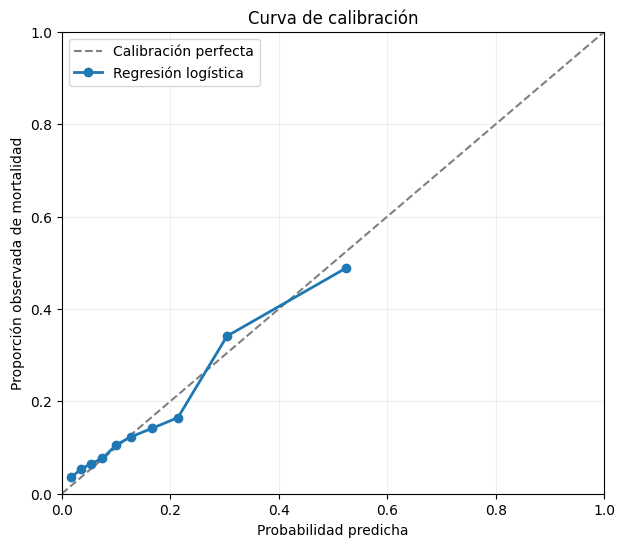

In [57]:
# Cálculo de las proporciones observadas y probabilidades medias
frecuencia_observada, probabilidad_media = calibration_curve(
    y_observada,
    p,
    n_bins=10,
    strategy="quantile"
)

# Gráfico de calibración
plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Calibración perfecta"
)

plt.plot(
    probabilidad_media,
    frecuencia_observada,
    marker="o",
    linewidth=2,
    label="Regresión logística"
)

plt.xlabel("Probabilidad predicha")
plt.ylabel("Proporción observada de mortalidad")
plt.title("Curva de calibración")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.2)
plt.show()